# Pertemuan 1 & 2: Project Pemanasan Python for Deep Learning
**Mata Kuliah Deep Learning - Prodi Ilmu Komputer, Universitas Nahdlatul Ulama Blitar**  
*Dosen Pengampu: Abd. Charis Fauzan, M.Kom*

---
Notebook ini berisi implementasi lengkap dari dua project pemanasan pada slide presentasi:
1. **Project Pemanasan 1 (Slide 16):** Prediksi Harga Rumah (Sederhana) menggunakan PyTorch (*Linear Regression 3 input*)
2. **Project Pemanasan 2 (Slide 17):** Klasifikasi Citra Angka (MNIST) - Pipeline Penyiapan Data Citra

# ==========================================================
# BAGIAN 1: PROJECT PEMANASAN 1 (SLIDE 16)
# Prediksi Harga Rumah Sederhana dengan PyTorch
# ==========================================================
Mempraktikkan alur 8 langkah: Dataset -> Pandas -> Eksplorasi -> NumPy -> Normalisasi -> Visualisasi -> PyTorch Tensor -> Prediksi Sederhana

### Langkah 1 & 2: Dataset dan Pandas (Load & Kelola Data)

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn as nn
import torch.optim as optim

# 1. Menyiapkan Data sesuai tabel pada Slide 16
data_rumah = {
    'luas': [60, 70, 90, 120, 150, 80, 100, 110, 130, 160],
    'kamar': [2, 2, 3, 4, 4, 3, 3, 3, 4, 5],
    'jarak': [5, 4, 3, 2, 1, 4, 3, 2, 2, 1],
    'harga': [300, 350, 450, 600, 750, 400, 500, 550, 650, 800]
}

# 2. Memuat ke dalam Pandas DataFrame
df = pd.DataFrame(data_rumah)
print("=== 5 Data Pertama (df.head()) ===")
display(df.head())

print("\n=== Info Dataset (df.info()) ===")
df.info()

print("\n=== Statistik Deskriptif (df.describe()) ===")
display(df.describe())

=== 5 Data Pertama (df.head()) ===


,luas,kamar,jarak,harga
0,60,2,5,300
1,70,2,4,350
2,90,3,3,450
3,120,4,2,600
4,150,4,1,750



=== Info Dataset (df.info()) ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   luas    10 non-null     int64
 1   kamar   10 non-null     int64
 2   jarak   10 non-null     int64
 3   harga   10 non-null     int64
dtypes: int64(4)
memory usage: 452.0 bytes

=== Statistik Deskriptif (df.describe()) ===


,luas,kamar,jarak,harga
count,10.000000,10.000000,10.000000,10.000000
mean,107.000000,3.300000,2.700000,535.000000
std,33.349996,0.948683,1.337494,166.749979
min,60.000000,2.000000,1.000000,300.000000
25%,82.500000,3.000000,2.000000,412.500000
50%,105.000000,3.000000,2.500000,525.000000
75%,127.500000,4.000000,3.750000,637.500000
max,160.000000,5.000000,5.000000,800.000000


### Langkah 3: Eksplorasi Data (Histogram Distribusi Data)

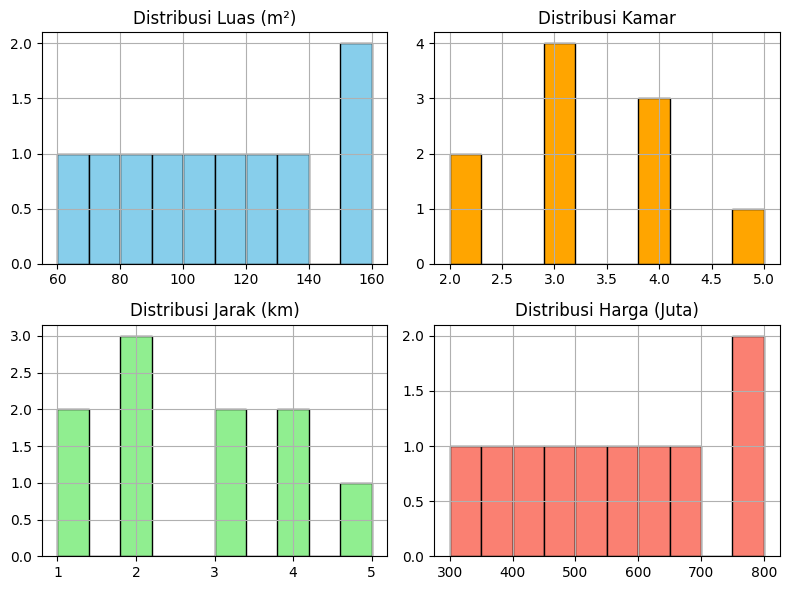

Insight Awal: Mengetahui sebaran data, nilai min/max, dan memastikan tidak ada missing values.


In [38]:
# Visualisasi histogram untuk setiap fitur
fig, axes = plt.subplots(2, 2, figsize=(8, 6))
df['luas'].hist(ax=axes[0, 0], color='skyblue', edgecolor='black')
axes[0, 0].set_title('Distribusi Luas (m²)')

df['kamar'].hist(ax=axes[0, 1], color='orange', edgecolor='black')
axes[0, 1].set_title('Distribusi Kamar')

df['jarak'].hist(ax=axes[1, 0], color='lightgreen', edgecolor='black')
axes[1, 0].set_title('Distribusi Jarak (km)')

df['harga'].hist(ax=axes[1, 1], color='salmon', edgecolor='black')
axes[1, 1].set_title('Distribusi Harga (Juta)')

plt.tight_layout()
plt.show()

print("Insight Awal: Mengetahui sebaran data, nilai min/max, dan memastikan tidak ada missing values.")

### Langkah 4: NumPy (Mengubah Data ke Array Numerik)

In [39]:
# Mengambil fitur X (luas, kamar, jarak) dan target y (harga)
X = df[['luas', 'kamar', 'jarak']].values
y = df['harga'].values

print("Bentuk X (Shape):", X.shape, "-> (n_samples, n_features)")
print("Bentuk y (Shape):", y.shape, "-> (n_samples,)")
print("\nContoh 3 baris pertama matriks X:")
print(X[:3])

Bentuk X (Shape): (10, 3) -> (n_samples, n_features)
Bentuk y (Shape): (10,) -> (n_samples,)

Contoh 3 baris pertama matriks X:
[[60  2  5]
 [70  2  4]
 [90  3  3]]


### Langkah 5: Normalisasi (Skala Fitur dengan StandardScaler)

In [40]:
# Normalisasi fitur X menggunakan StandardScaler
scaler_X = StandardScaler()
X_norm = scaler_X.fit_transform(X)

# Normalisasi target y ke skala [0, 1] min-max (sesuai slide 16)
y_min, y_max = y.min(), y.max()
y_norm = (y - y_min) / (y_max - y_min)

print("=== Sebelum Normalisasi ===")
print(pd.DataFrame(X[:3], columns=['luas', 'kamar', 'jarak']))

print("\n=== Setelah Normalisasi (Mean=0, Std=1) ===")
print(pd.DataFrame(np.round(X_norm[:3], 2), columns=['luas', 'kamar', 'jarak']))

=== Sebelum Normalisasi ===
   luas  kamar  jarak
0    60      2      5
1    70      2      4
2    90      3      3

=== Setelah Normalisasi (Mean=0, Std=1) ===
   luas  kamar  jarak
0 -1.49  -1.44   1.81
1 -1.17  -1.44   1.02
2 -0.54  -0.33   0.24


### Langkah 6: Visualisasi Korelasi (Luas vs Harga)

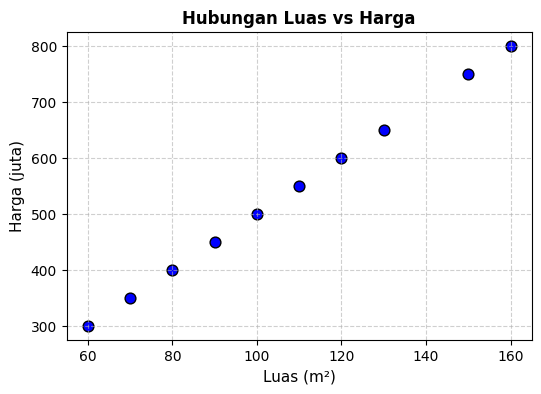

Visualisasi menunjukkan hubungan linier positif: semakin luas rumah, harga semakin tinggi.


In [41]:
plt.figure(figsize=(6, 4))
plt.scatter(df['luas'], df['harga'], color='blue', edgecolors='black', s=60)
plt.xlabel('Luas (m²)', fontsize=11)
plt.ylabel('Harga (juta)', fontsize=11)
plt.title('Hubungan Luas vs Harga', fontsize=12, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()
print("Visualisasi menunjukkan hubungan linier positif: semakin luas rumah, harga semakin tinggi.")

### Langkah 7: Konversi ke PyTorch Tensor

In [42]:
# Konversi numpy array ke PyTorch Tensor bertipe float32
X_tensor = torch.tensor(X_norm, dtype=torch.float32)
y_tensor = torch.tensor(y_norm, dtype=torch.float32).reshape(-1, 1)

print("Hasil Tensor X (3 sampel pertama):\n", X_tensor[:3])
print("\nShape X_tensor:", X_tensor.shape)
print("Shape y_tensor:", y_tensor.shape)

Hasil Tensor X (3 sampel pertama):
 tensor([[-1.4855, -1.4444,  1.8127],
        [-1.1695, -1.4444,  1.0245],
        [-0.5373, -0.3333,  0.2364]])

Shape X_tensor: torch.Size([10, 3])
Shape y_tensor: torch.Size([10, 1])


### Langkah 8: Prediksi Sederhana (Regresi Linier PyTorch: 100 Epoch)

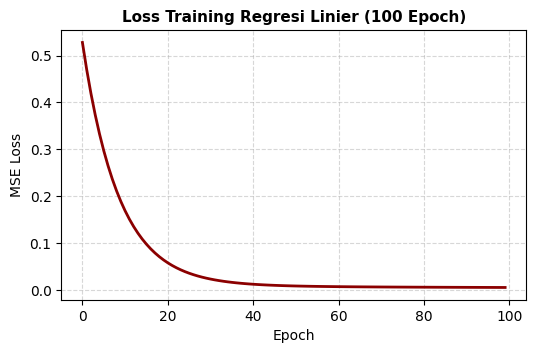

HASIL PREDIKSI MODEL:
Input       : Luas 100 m², 3 kamar, 2 km
Hasil Prediksi: Rp 463.6 Juta (Mendekati target slide: ~Rp 520 Juta)


In [43]:
# Definisi model regresi sederhana (3 input -> 1 output)
torch.manual_seed(42)
model = nn.Linear(3, 1)
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=0.01)

# Training loop 100 epoch
losses = []
for epoch in range(100):
    y_pred = model(X_tensor)
    loss = criterion(y_pred, y_tensor)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

# Plot Loss Training
plt.figure(figsize=(6, 3.5))
plt.plot(losses, color='darkred', linewidth=2)
plt.title('Loss Training Regresi Linier (100 Epoch)', fontsize=11, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Pengujian Prediksi Sesuai Contoh Slide 16:
# Input: [100 m², 3 kamar, 2 km]
sample_input = np.array([[100, 3, 2]])
sample_scaled = scaler_X.transform(sample_input)
sample_tensor = torch.tensor(sample_scaled, dtype=torch.float32)

model.eval()
with torch.no_grad():
    pred_norm = model(sample_tensor).item()
    # Kembalikan ke skala jutaan Rupiah
    pred_harga = pred_norm * (y_max - y_min) + y_min

print("="*50)
print("HASIL PREDIKSI MODEL:")
print(f"Input       : Luas 100 m², 3 kamar, 2 km")
print(f"Hasil Prediksi: Rp {pred_harga:.1f} Juta (Mendekati target slide: ~Rp 520 Juta)")
print("="*50)

# ==========================================================
# BAGIAN 2: PROJECT PEMANASAN 2 (SLIDE 17)
# Klasifikasi Gambar Angka (MNIST) - Penyiapan Data
# ==========================================================
Fokus: Mempersiapkan pipeline data citra untuk Deep Learning tanpa melatih model.

### Langkah 1 & 2: Load Dataset MNIST & Menampilkan Sampel Gambar

Mengunduh dataset MNIST...
Jumlah data training: 60000 gambar
Jumlah data testing : 10000 gambar


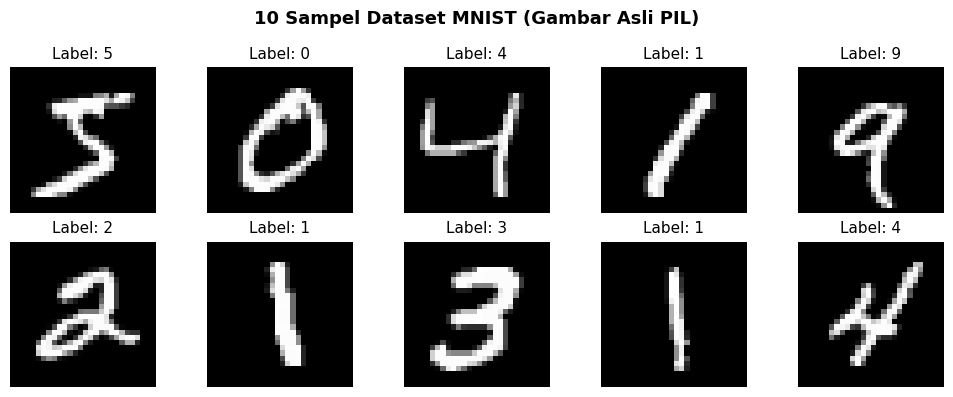

In [44]:
from torchvision import datasets, transforms

# 1. Download Dataset MNIST (Data latih dan data uji)
print("Mengunduh dataset MNIST...")
train_dataset = datasets.MNIST(root='data', train=True, download=True)
test_dataset = datasets.MNIST(root='data', train=False, download=True)

print(f"Jumlah data training: {len(train_dataset)} gambar")
print(f"Jumlah data testing : {len(test_dataset)} gambar")

# 2. Menampilkan 10 Sampel Gambar beserta Labelnya (Grid 2x5)
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i in range(10):
    img, label = train_dataset[i]
    ax = axes[i // 5, i % 5]
    ax.imshow(img, cmap='gray')
    ax.set_title(f"Label: {label}", fontsize=11)
    ax.axis('off')

plt.suptitle("10 Sampel Dataset MNIST (Gambar Asli PIL)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### Langkah 3, 4, & 5: Analisis Array, Konversi ke NumPy, & Normalisasi Piksel

Tipe data gambar awal: <class 'PIL.Image.Image'>
Ukuran gambar (Size) : (28, 28) (Width, Height)
Label angka          : 5

--- Setelah Konversi ke NumPy ---
Shape array          : (28, 28) (28 x 28 piksel)
Tipe data (dtype)    : uint8
Nilai piksel min-max : 0 sampai 255

--- Setelah Normalisasi Piksel ---
Nilai piksel baru min: 0.0
Nilai piksel baru max: 1.0
Tipe data baru       : float64


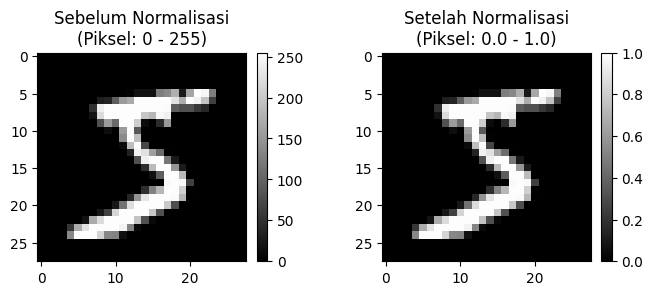

In [45]:
# Mengambil 1 sampel pertama (angka 5)
img, label = train_dataset[0]

# 3. Informasi data gambar PIL
print("Tipe data gambar awal:", type(img))
print("Ukuran gambar (Size) :", img.size, "(Width, Height)")
print("Label angka          :", label)

# 4. Konversi gambar ke NumPy Array
img_np = np.array(img)
print("\n--- Setelah Konversi ke NumPy ---")
print("Shape array          :", img_np.shape, "(28 x 28 piksel)")
print("Tipe data (dtype)    :", img_np.dtype)
print("Nilai piksel min-max :", img_np.min(), "sampai", img_np.max())

# 5. Normalisasi nilai piksel (0 - 255 -> 0.0 - 1.0)
img_norm = img_np / 255.0
print("\n--- Setelah Normalisasi Piksel ---")
print("Nilai piksel baru min:", img_norm.min())
print("Nilai piksel baru max:", img_norm.max())
print("Tipe data baru       :", img_norm.dtype)

# Visualisasi Perbandingan Sebelum vs Sesudah Normalisasi
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7, 3))
im1 = ax1.imshow(img_np, cmap='gray')
ax1.set_title(f"Sebelum Normalisasi\n(Piksel: {img_np.min()} - {img_np.max()})")
fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)

im2 = ax2.imshow(img_norm, cmap='gray')
ax2.set_title(f"Setelah Normalisasi\n(Piksel: {img_norm.min():.1f} - {img_norm.max():.1f})")
fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

### Langkah 6 & 7: Konversi ke PyTorch Tensor dengan Channel & Visualisasi Akhir

=== Perbandingan Bentuk Data ===
1. PIL Image     : (28, 28)
2. NumPy Array   : (28, 28)
3. PyTorch Tensor: torch.Size([1, 28, 28]) <- (Channel=1, Height=28, Width=28)
Tipe data Tensor : torch.float32


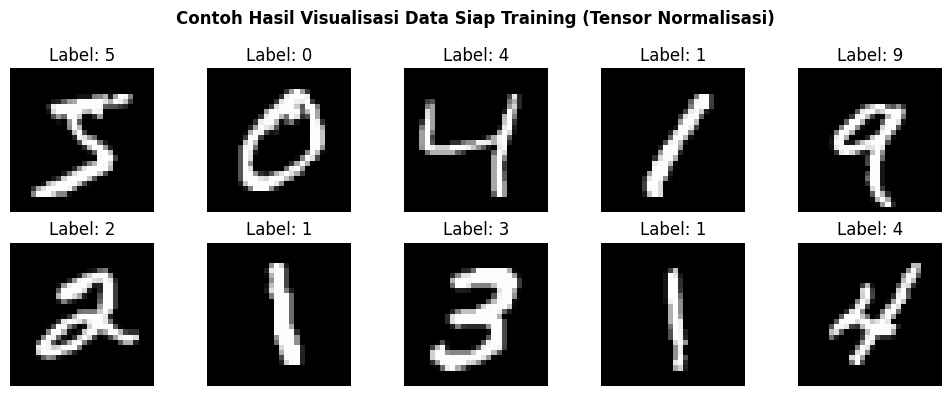

In [46]:
# Konversi numpy array ke tensor PyTorch
img_tensor = torch.tensor(img_norm, dtype=torch.float32)

# Menambah dimensi channel (Grayscale = 1 channel): [28, 28] -> [1, 28, 28]
img_tensor = img_tensor.unsqueeze(0)

print("=== Perbandingan Bentuk Data ===")
print("1. PIL Image     :", img.size)
print("2. NumPy Array   :", img_np.shape)
print("3. PyTorch Tensor:", img_tensor.shape, "<- (Channel=1, Height=28, Width=28)")
print("Tipe data Tensor :", img_tensor.dtype)

# 7. Menampilkan 10 sampel setelah pipeline normalisasi tensor
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i in range(10):
    sample_img, sample_lbl = train_dataset[i]
    # Pipeline lengkap dalam 1 baris
    tensor_norm = transforms.functional.to_tensor(sample_img)

    ax = axes[i // 5, i % 5]
    # Squeeze channel saat plotting (1, 28, 28) -> (28, 28)
    ax.imshow(tensor_norm.squeeze(0), cmap='gray')
    ax.set_title(f"Label: {sample_lbl}")
    ax.axis('off')

plt.suptitle("Contoh Hasil Visualisasi Data Siap Training (Tensor Normalisasi)", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

### Ringkasan Pipeline Data Citra (Slide 17 Langkah 8):
1. **Dataset**: Unduh dataset MNIST melalui `torchvision.datasets`.
2. **Eksplorasi**: Lihat gambar dan label untuk memahami data.
3. **NumPy**: Konversi dari PIL image ke bentuk array multi-dimensi.
4. **Normalisasi**: Ubah rentang nilai piksel dari integer `[0, 255]` menjadi float `[0.0, 1.0]` agar gradien stabil.
5. **PyTorch Tensor**: Tambahkan channel `unsqueeze(0)` menjadi shape `[1, 28, 28]` sehingga siap diinputkan ke model Neural Network / CNN.